In [ ]:
1. The data from the Berkeley Guidance study included the coding for gender 
as: 0 = males, 1= females. Generated a scatter-plot matrix of all continuous 
variables. Grouped the variables by gender so that each paired observation has 
a gender-associated label. Explained the relationships that you see.

2. Generated two linear regressions that predict WT18 (weight at 18 years old).


One regression model is to predict the weight of boys, and the other is to 
predict the weight of girls. Interpreted the results. Generated a multiple linear
regression model to explain WT18 using the variables HT2, WT2, HT9, WT9, and 
ST9. Found the R-squared, the overall ANOVA table, and the overall F-test. 
Compute the t-statistics to test each of the coefficients against to be 0. 
State the conclusions from this test.   

3. Used t-tests to accept or reject the statements listed below. Stated 
conclusions using the terminology of hypothesis testing. 

There is no difference in cholesterol between males and females. 

There is no difference in diastolic blood pressure between males and females. 

4. Created 2 simple linear regression models that predict cholesterol: 


For the first model, use a continuous variable that exhibits the best 
correlation with the dependent variable.
For the second model, use a continuous variable that exhibits the next best 
correlation with the dependent variable.
Explain and support the difference between the models from the previous two 
steps. 

5. Created a multiple regression model that uses all of the continuous variables. 


Explained and supported the results of the model.

Compared the performance of the multiple regression model with the best 
bilinear regression model from question 4 (the bilinear model). 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [3]:
# Loaded datasets
bg = pd.read_csv("HW2_BGALL.csv")
heart = pd.read_csv("HW2_HW3_HEART.csv")

# Checked datasets
print("Berkeley Guidance shape:", bg.shape)
print(bg.head())

print("\nHeart dataset shape:", heart.shape)
print(heart.head())

Berkeley Guidance shape: (136, 12)
   Sex   WT2   HT2   WT9    HT9   LG9  ST9   WT18   HT18  LG18  ST18  Soma
0    0  13.6  90.2  41.5  139.4  31.6   74  110.2  179.0  44.1   226   7.0
1    0  12.7  91.4  31.0  144.3  26.0   73   79.4  195.1  36.1   252   4.0
2    0  12.6  86.4  30.1  136.5  26.6   64   76.3  183.7  36.9   216   6.0
3    0  14.8  87.6  34.1  135.4  28.2   75   74.5  178.7  37.3   220   2.0
4    0  12.7  86.7  24.5  128.9  24.2   63   55.7  171.5  31.0   200   1.5

Heart dataset shape: (5209, 17)
  Status DeathCause  AgeCHDdiag     Sex  AgeAtStart  Height  Weight  \
0   Dead      Other         NaN  Female          29   62.50   140.0   
1   Dead     Cancer         NaN  Female          41   59.75   194.0   
2  Alive        NaN         NaN  Female          57   62.25   132.0   
3  Alive        NaN         NaN  Female          39   65.75   158.0   
4  Alive        NaN         NaN    Male          42   66.00   156.0   

   Diastolic  Systolic    MRW  Smoking  AgeAtDeath  Cho

In [ ]:
Q1: Scatter-plot matrix of continous variables by gender

In [4]:
# Sex coding: 0 = male, 1 = female
bg["Gender"] = bg["Sex"].map({0: "Male", 1: "Female"})

# Continuous variables from Berkeley Guidance dataset
bg_continuous = ["WT2", "HT2", "WT9", "HT9", "LG9", "ST9", 
                 "WT18", "HT18", "LG18", "ST18", "Soma"]

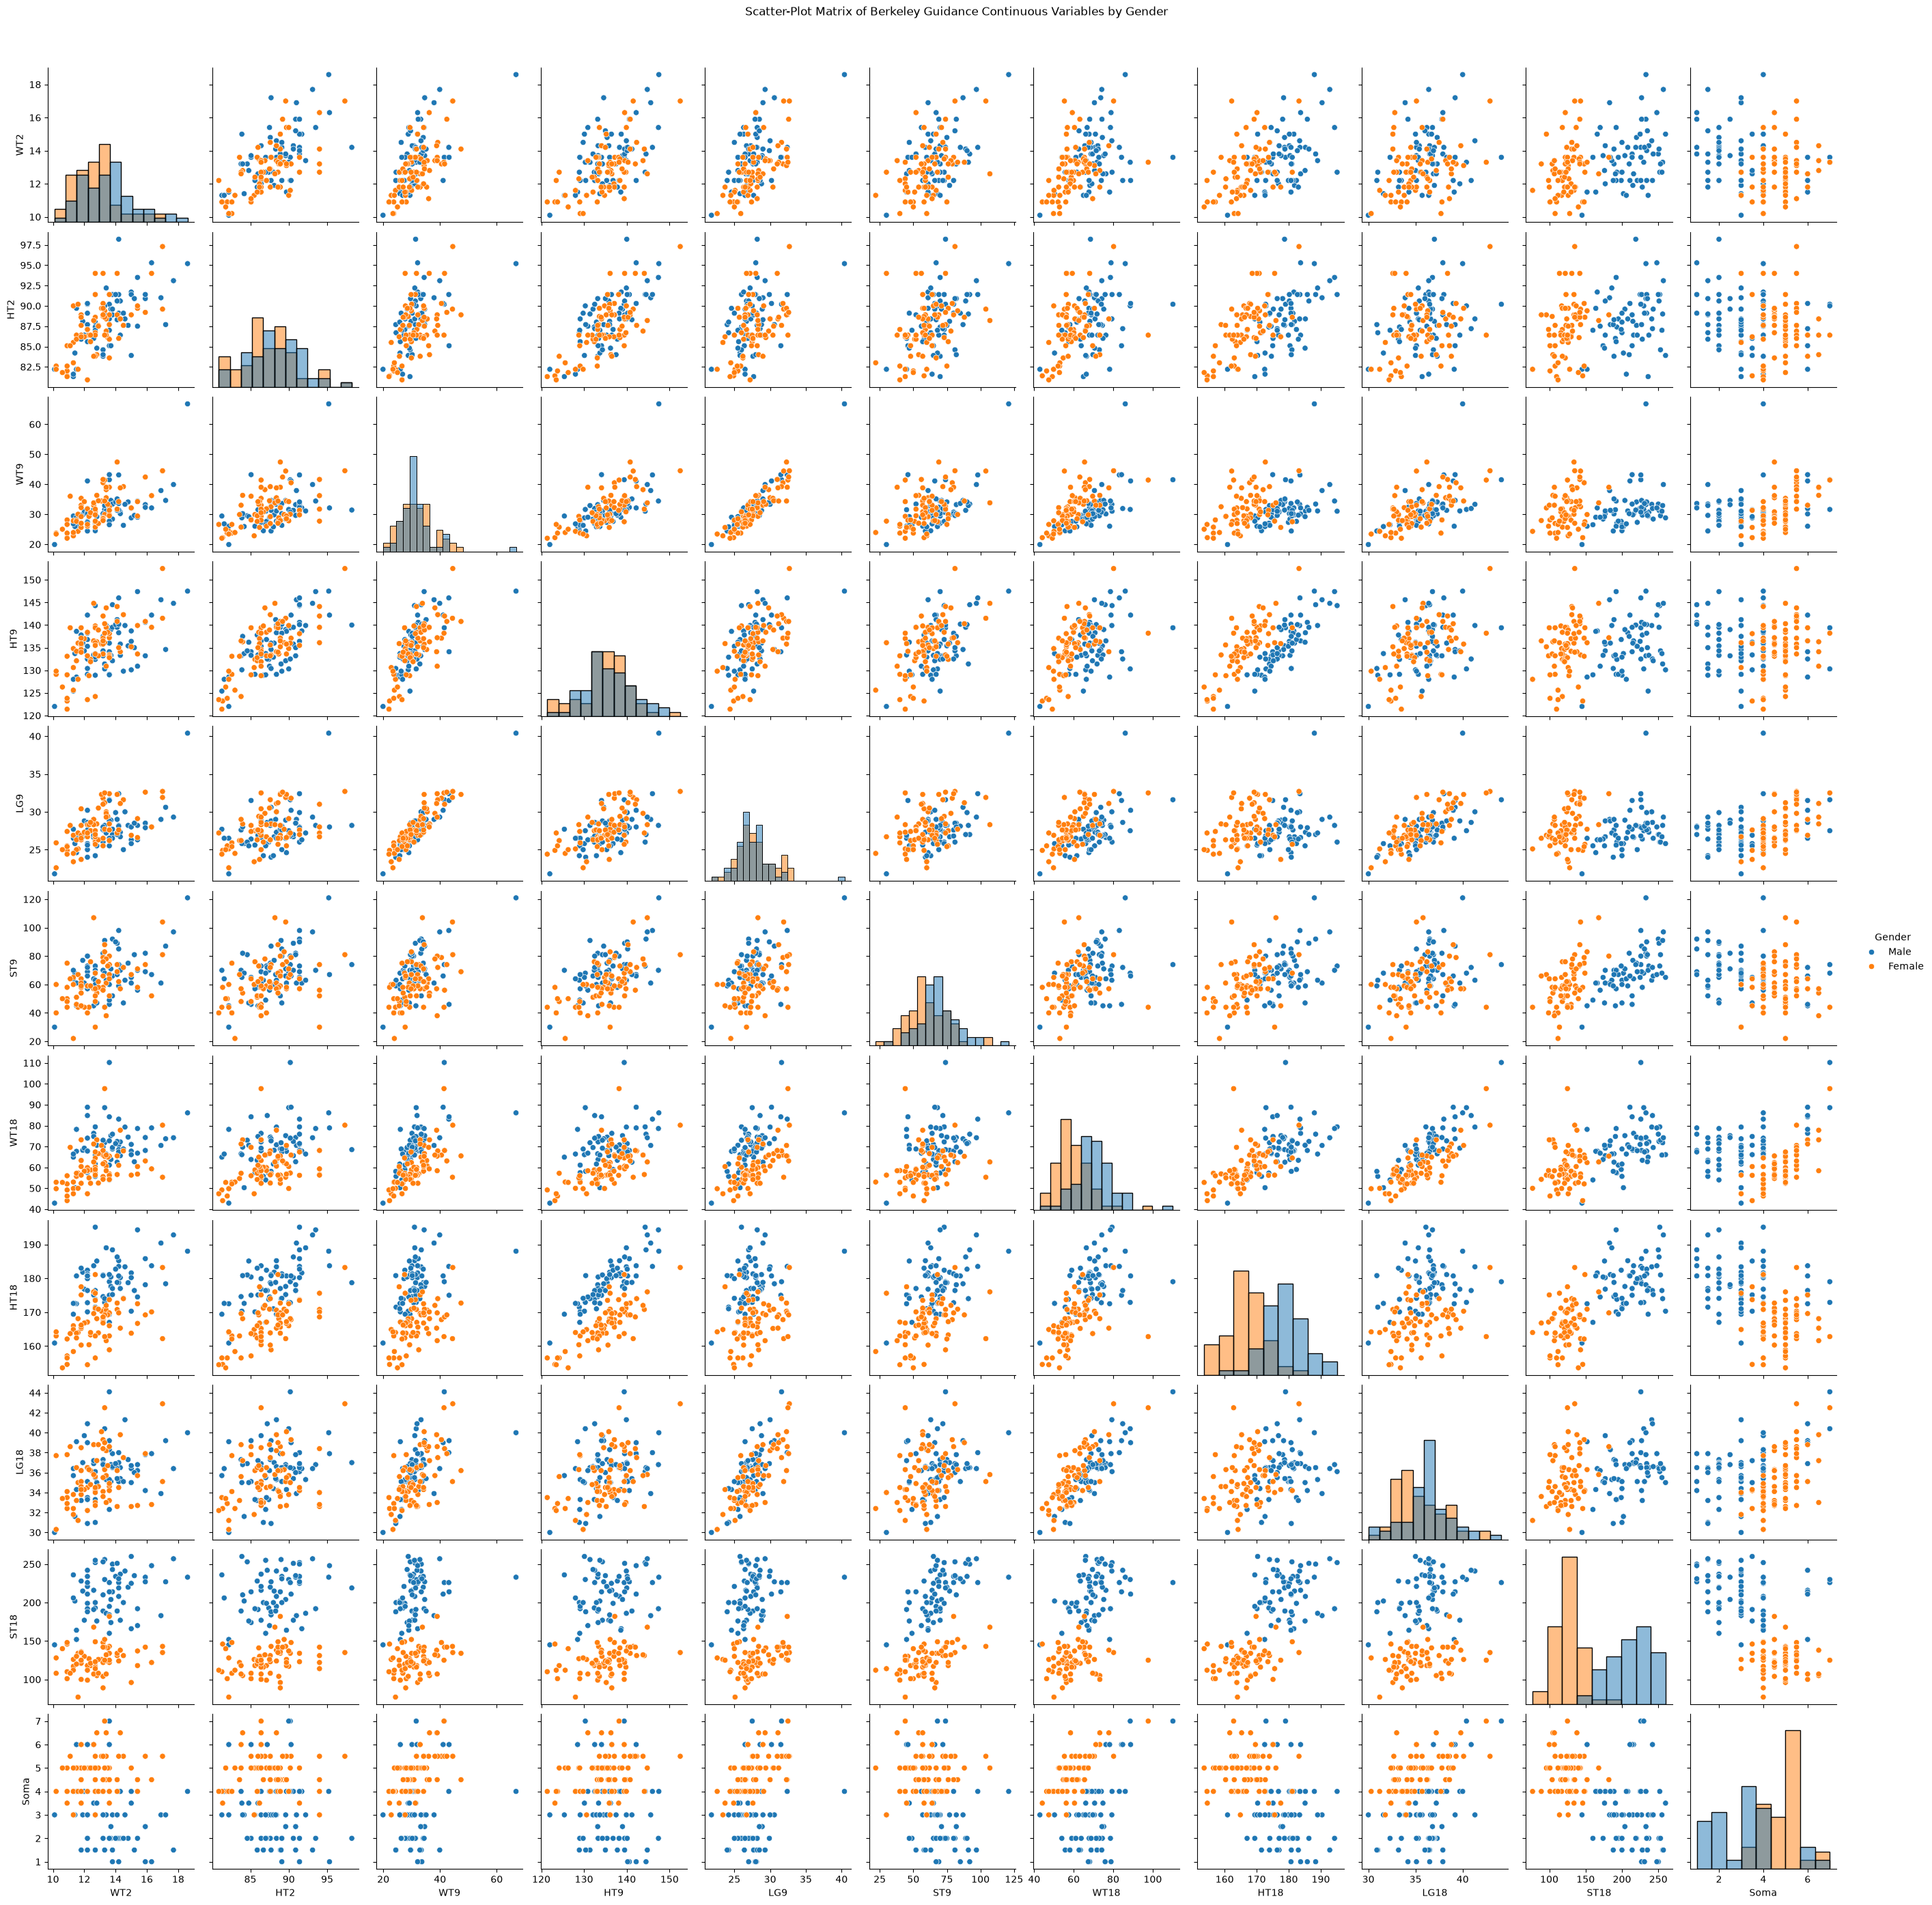

Correlation Matrix:


,WT2,HT2,WT9,HT9,LG9,ST9,WT18,HT18,LG18,ST18,Soma
WT2,1.000,0.639,0.619,0.561,0.558,0.491,0.416,0.486,0.305,0.342,-0.188
HT2,0.639,1.000,0.498,0.721,0.428,0.436,0.391,0.549,0.292,0.276,-0.176
WT9,0.619,0.498,1.000,0.687,0.920,0.496,0.581,0.314,0.584,0.153,0.283
HT9,0.561,0.721,0.687,1.000,0.573,0.555,0.499,0.643,0.401,0.205,-0.012
LG9,0.558,0.428,0.920,0.573,1.000,0.467,0.533,0.199,0.698,0.101,0.315
ST9,0.491,0.436,0.496,0.555,0.467,1.000,0.359,0.468,0.311,0.510,-0.230
WT18,0.416,0.391,0.581,0.499,0.533,0.359,1.000,0.624,0.793,0.564,0.119
HT18,0.486,0.549,0.314,0.643,0.199,0.468,0.624,1.000,0.302,0.709,-0.461
LG18,0.305,0.292,0.584,0.401,0.698,0.311,0.793,0.302,1.000,0.292,0.311
ST18,0.342,0.276,0.153,0.205,0.101,0.510,0.564,0.709,0.292,1.000,-0.571


In [5]:
# Scatter-plot matrix grouped by gender
sns.pairplot(bg, vars=bg_continuous, hue="Gender", diag_kind="hist")
plt.suptitle("Scatter-Plot Matrix of Berkeley Guidance Continuous Variables by Gender", y=1.02)
plt.show()

# Correlation matrix
bg_corr = bg[bg_continuous].corr()
print("Correlation Matrix:")
display(bg_corr.round(3))

In [6]:
# Strongest correlations with WT18
print("\nCorrelations with WT18:")
display(bg_corr["WT18"].sort_values(ascending=False).round(3))

# Group means by gender
print("\nMean values by gender:")
display(bg.groupby("Gender")[bg_continuous].mean().round(2))


Correlations with WT18:


WT18    1.000
LG18    0.793
HT18    0.624
WT9     0.581
ST18    0.564
LG9     0.533
HT9     0.499
WT2     0.416
HT2     0.391
ST9     0.359
Soma    0.119
Name: WT18, dtype: float64


Mean values by gender:


,WT2,HT2,WT9,HT9,LG9,ST9,WT18,HT18,LG18,ST18,Soma
Gender,,,,,,,,,,,
Female,12.82,87.25,31.62,135.12,27.84,60.46,59.78,166.54,35.42,124.74,4.78
Male,13.63,88.37,31.63,135.89,27.50,68.92,70.27,178.98,36.29,212.09,3.09


In [ ]:
The scatter-plot matrix and correlation matrix show that most body-size variables 
have positive relationships. The strongest relationship with WT18 is LG18, with a 
correlation of 0.793, meaning students with larger leg measurements at age 18 
tended to weigh more at age 18. HT18 was also strongly related to WT18, with a 
correlation of 0.624. Earlier measurements had moderate relationships with WT18, 
such as WT9 = 0.581 and LG9 = 0.533, showing that body size at age 9 was somewhat 
connected to weight at age 18.

The matrix also shows strong relationships among other growth variables. For 
example, WT9 and LG9 had a very strong correlation of 0.920, and HT2 and HT9 had 
a correlation of 0.721. However, Soma did not show strong positive relationships 
with most variables. Overall, height, weight, and leg measurements tend to 
increase together, while Soma appears to follow a different pattern.

In [ ]:
Q2: PART A -  Separate regression models for boys and girls
# Predict WT18 using HT2, WT2, HT9, WT9, and ST9

In [15]:
predictors = ["HT2", "WT2", "HT9", "WT9", "ST9"]

boys = bg[bg["Sex"] == 0].copy()
girls = bg[bg["Sex"] == 1].copy()

formula = "WT18 ~ HT2 + WT2 + HT9 + WT9 + ST9"

boys_model = smf.ols(formula, data=boys).fit()
girls_model = smf.ols(formula, data=girls).fit()

print("BOYS MODEL SUMMARY")
print(boys_model.summary())

print("\nGIRLS MODEL SUMMARY")
print(girls_model.summary())

BOYS MODEL SUMMARY
                            OLS Regression Results                            
Dep. Variable:                   WT18   R-squared:                       0.444
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     9.596
Date:                Sat, 04 Jul 2026   Prob (F-statistic):           9.13e-07
Time:                        09:16:53   Log-Likelihood:                -225.58
No. Observations:                  66   AIC:                             463.2
Df Residuals:                      60   BIC:                             476.3
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.5717     31.925 

In [ ]:
The boys regression model predicting WT18 had an R-squared of 0.444, meaning the 
model explains about 44.4% of the variation in weight at age 18 for boys. The 
overall model was statistically significant, F = 9.596, p = 9.13e-07, so we reject
the null hypothesis that all predictors are equal to zero. However, when looking at
the individual variables, only WT9 was statistically significant, with a 
coefficient of 1.1346, t = 4.769, and p < 0.001. This means that, for boys, higher
weight at age 9 was the strongest predictor of weight at age 18.

The girls regression model had a stronger fit, with an R-squared of 0.577, 
meaning the model explains about 57.7% of the variation in weight at age 18 for 
girls. The overall model was also statistically significant, F = 17.46, 
p = 7.24e-11. For girls, several variables were significant: HT9 had a coefficient
of 0.8442 with p = 0.002, WT9 had a coefficient of 0.8738 with p < 0.001, and ST9
had a coefficient of -0.1615 with p = 0.010. This suggests that age 9 measurements
were more useful for predicting weight at age 18 for girls than for boys. Overall,
the girls model performed better because it had the higher R-squared value.

In [ ]:
Q3: T-tests comparing males and females

In [16]:
def independent_ttest_by_sex(data, variable):
    male = data.loc[data["Sex"] == "Male", variable].dropna()
    female = data.loc[data["Sex"] == "Female", variable].dropna()
    
    t_stat, p_value = stats.ttest_ind(male, female, equal_var=False)
    
    results = {
        "Variable": variable,
        "Male Mean": male.mean(),
        "Female Mean": female.mean(),
        "Male N": len(male),
        "Female N": len(female),
        "t-statistic": t_stat,
        "p-value": p_value
    }
    
    return results

chol_test = independent_ttest_by_sex(heart, "Cholesterol")
dias_test = independent_ttest_by_sex(heart, "Diastolic")

ttest_results = pd.DataFrame([chol_test, dias_test])
display(ttest_results.round(4))

,Variable,Male Mean,Female Mean,Male N,Female N,t-statistic,p-value
0,Cholesterol,226.0512,228.5418,2283,2774,-1.9814,0.0476
1,Diastolic,86.2346,84.6464,2336,2873,4.4333,0.0000


In [ ]:
The first t-test examined whether there is a difference in cholesterol between male
s and females. The male mean was 226.05, and the female mean was 228.54. Since the
p-value was 0.0476, which is less than 0.05, we reject the null hypothesis. This 
means there is a statistically significant difference in cholesterol between males
and females.

The second t-test examined whether there is a difference in diastolic blood 
pressure between males and females. The male mean was 86.23, and the female mean 
was 84.65. Since the p-value was 0.0000, which is less than 0.05, we reject the 
null hypothesis. This means there is a statistically significant difference in 
diastolic blood pressure between males and females.

In [ ]:
Q4: Part 1 - Find the two continuous variables with strongest correlation to Cholesterol

In [19]:
heart_numeric = heart.select_dtypes(include=np.number)

# Correlations with Cholesterol
chol_corr = heart_numeric.corr()["Cholesterol"].drop("Cholesterol").dropna()

# Sorted by absolute value because negative and positive relationships both matter
chol_corr_sorted = chol_corr.reindex(chol_corr.abs().sort_values(ascending=False).index)

print("Correlations with Cholesterol:")
display(chol_corr_sorted.round(3))

best_var = chol_corr_sorted.index[0]
second_best_var = chol_corr_sorted.index[1]

print("Best predictor:", best_var)
print("Second best predictor:", second_best_var)

Correlations with Cholesterol:


AgeAtStart    0.273
Systolic      0.199
Diastolic     0.183
MRW           0.137
Height       -0.080
AgeAtDeath    0.078
Weight        0.072
Smoking      -0.012
AgeCHDdiag    0.004
Name: Cholesterol, dtype: float64

Best predictor: AgeAtStart
Second best predictor: Systolic


In [ ]:
Q4: Part 2 - Build two simple regression models

In [20]:
model1_data = heart[["Cholesterol", best_var]].dropna()
model2_data = heart[["Cholesterol", second_best_var]].dropna()

model1 = smf.ols(f"Cholesterol ~ {best_var}", data=model1_data).fit()
model2 = smf.ols(f"Cholesterol ~ {second_best_var}", data=model2_data).fit()

print("MODEL 1 SUMMARY")
print(model1.summary())

print("\nMODEL 2 SUMMARY")
print(model2.summary())

MODEL 1 SUMMARY
                            OLS Regression Results                            
Dep. Variable:            Cholesterol   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.075
Method:                 Least Squares   F-statistic:                     408.4
Date:                Sat, 04 Jul 2026   Prob (F-statistic):           2.12e-87
Time:                        09:29:42   Log-Likelihood:                -26222.
No. Observations:                5057   AIC:                         5.245e+04
Df Residuals:                    5055   BIC:                         5.246e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    164.2427      3.185    

In [21]:
# Compared models
simple_compare = pd.DataFrame({
    "Model": [f"Cholesterol ~ {best_var}", f"Cholesterol ~ {second_best_var}"],
    "R-squared": [model1.rsquared, model2.rsquared],
    "Adjusted R-squared": [model1.rsquared_adj, model2.rsquared_adj],
    "F-statistic": [model1.fvalue, model2.fvalue],
    "p-value": [model1.f_pvalue, model2.f_pvalue],
    "RMSE": [
        np.sqrt(np.mean(model1.resid ** 2)),
        np.sqrt(np.mean(model2.resid ** 2))
    ]
})

display(simple_compare.round(4))

,Model,R-squared,Adjusted R-squared,F-statistic,p-value,RMSE
0,Cholesterol ~ AgeAtStart,0.0748,0.0746,408.4212,0.0,43.2190
1,Cholesterol ~ Systolic,0.0397,0.0396,209.2023,0.0,44.0292


In [ ]:
The AgeAtStart model performed better than the Systolic model. AgeAtStart had a 
higher R-squared of 0.0748, meaning it explained about 7.48% of cholesterol 
variation, while Systolic only explained 3.97%. AgeAtStart also had a lower RMSE 
of 43.2190, compared to 44.0292 for Systolic.

Both models were statistically significant because both p-values were 0.0000, but 
neither model explains a large amount of cholesterol variation. Overall, 
AgeAtStart is the stronger predictor, but cholesterol is likely influenced by 
multiple variables, not just one.

In [ ]:
Q5: Part 1 - Multiple regression model using all continuous variables
Dependent variable: Cholesterol

In [22]:
# All continuous predictors except Cholesterol
all_predictors = [col for col in heart_numeric.columns if col != "Cholesterol"]

print("Continuous predictors used:")
print(all_predictors)

# Dropped rows with missing values for the model
multi_data = heart[["Cholesterol"] + all_predictors].dropna()

multi_formula = "Cholesterol ~ " + " + ".join(all_predictors)

multi_model = smf.ols(multi_formula, data=multi_data).fit()

print(multi_model.summary())

Continuous predictors used:
['AgeCHDdiag', 'AgeAtStart', 'Height', 'Weight', 'Diastolic', 'Systolic', 'MRW', 'Smoking', 'AgeAtDeath']
                            OLS Regression Results                            
Dep. Variable:            Cholesterol   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     3.612
Date:                Sat, 04 Jul 2026   Prob (F-statistic):           0.000197
Time:                        09:34:02   Log-Likelihood:                -4563.5
No. Observations:                 864   AIC:                             9147.
Df Residuals:                     854   BIC:                             9195.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.97

In [23]:
# Coefficient table
multi_coef_table = pd.DataFrame({
    "Coefficient": multi_model.params,
    "t-statistic": multi_model.tvalues,
    "p-value": multi_model.pvalues
})

display(multi_coef_table.round(4))

# RMSE for multiple model
multi_rmse = np.sqrt(np.mean(multi_model.resid ** 2))

print("Multiple Regression RMSE:", round(multi_rmse, 4))
print("Multiple Regression R-squared:", round(multi_model.rsquared, 4))
print("Multiple Regression Adjusted R-squared:", round(multi_model.rsquared_adj, 4))

,Coefficient,t-statistic,p-value
Intercept,352.5488,2.4107,0.0161
AgeCHDdiag,-0.5187,-2.0604,0.0397
AgeAtStart,0.2796,0.9456,0.3446
Height,-1.3649,-0.6062,0.5445
Weight,-0.0768,-0.1841,0.8540
Diastolic,0.0765,0.3896,0.6969
Systolic,0.0582,0.5741,0.5661
MRW,0.1543,0.2956,0.7676
Smoking,-0.0332,-0.2472,0.8048
AgeAtDeath,-0.2913,-1.0176,0.3092


Multiple Regression RMSE: 47.602
Multiple Regression R-squared: 0.0367
Multiple Regression Adjusted R-squared: 0.0265


In [ ]:
Q5: Part 2 - Compare multiple regression model with best two-variable model

In [24]:
two_predictor_data = heart[["Cholesterol", best_var, second_best_var]].dropna()

two_predictor_formula = f"Cholesterol ~ {best_var} + {second_best_var}"

two_predictor_model = smf.ols(two_predictor_formula, data=two_predictor_data).fit()

two_predictor_rmse = np.sqrt(np.mean(two_predictor_model.resid ** 2))

In [25]:
comparison = pd.DataFrame({
    "Model": [
        f"Two-predictor model: {best_var} + {second_best_var}",
        "Multiple regression model: all continuous variables"
    ],
    "N Used": [
        int(two_predictor_model.nobs),
        int(multi_model.nobs)
    ],
    "R-squared": [
        two_predictor_model.rsquared,
        multi_model.rsquared
    ],
    "Adjusted R-squared": [
        two_predictor_model.rsquared_adj,
        multi_model.rsquared_adj
    ],
    "F-statistic": [
        two_predictor_model.fvalue,
        multi_model.fvalue
    ],
    "p-value": [
        two_predictor_model.f_pvalue,
        multi_model.f_pvalue
    ],
    "RMSE": [
        two_predictor_rmse,
        multi_rmse
    ]
})

display(comparison.round(4))

print(two_predictor_model.summary())

In [ ]:
The two-predictor model using AgeAtStart and Systolic explained about 8.54% of 
cholesterol variation with an R-squared of 0.0854. The model was statistically 
significant, F = 235.8422, p = 0.0000, and both predictors were significant.

The full multiple regression model had a slightly higher R-squared of 0.0867, but 
its adjusted R-squared was much lower at 0.0265, and its RMSE was higher at 
47.6020. The two-predictor model is better because it is simpler, used more 
observations 5,057 vs. 864, and had a lower RMSE of 42.9706.